# Project B | 상품군별 주간 수요 시계열 탐색

**프로젝트 목표:** Olist 이커머스 데이터의 상품군별 주간 주문 상품 수량을 분석하고, 향후 1~4주 예측을 위한 수요 특성과 모델링의 기초 가정을 검토한다.

**분석 단위와 정의**
- 분석 대상: 학습 기간 주문 상품 수량 상위 5개 상품군
- 전체 분석 기간: 2017-03-06 ~ 2018-08-19 (**76주**, 주 시작일 기준)
- 학습: 2017-03-06 ~ 2018-05-27 (마지막 주 시작일 2018-05-21) (**64주**, 320행)
- 최종 평가: 2018-05-28 ~ 2018-08-19 (마지막 주 시작일 2018-08-13) (**12주**, 60행)
- 관측 단위: `product_category_name` × `week_start`
- 목표변수: `weekly_items` = 구매 시점 기준 주문 상품 항목 수
- 출처: PostgreSQL View `analytics.v_weekly_category_demand`

**분석 시 주의사항**
- 현재 목표변수는 주문 상태를 별도로 제한하지 않으며, 취소·미완료 주문도 포함한다. 완료된 판매량이나 잠재 수요와 동일하지 않다.
- 상품군 TOP 5는 최종 평가 기간을 제외한 학습 64주로 선정했다.
- 탐색·모형 선정에는 최종 평가 12주의 결과를 사용하지 않는다.
- 연간 계절성 추정에 필요한 반복 주기가 충분하지 않다.

**재현 방법:** [원본 CSV 적재 및 Python 환경 준비](../../A_delivery_quality/README.md#데이터-준비)를 따른다. PostgreSQL에서 `CREATE SCHEMA IF NOT EXISTS analytics;`를 실행한 뒤 [시계열 데이터 구축 SQL](../sql/01_data_validation_and_time_series.sql)로 분석용 뷰를 생성한다. 저장소 루트에서 Jupyter를 열고, 의존성을 설치한 Python 커널로 전체 셀을 실행한다. 루트의 로컬 `.env`에 접속 정보를 설정하고 마지막 검증 셀의 `PASS`를 확인한다.

In [1]:
import sys
print(sys.version)

3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

print('pandas:', pd.__version__)
print('라이브러리 불러오기 성공')

pandas: 3.1.1
라이브러리 불러오기 성공


In [3]:
# 1. 환경변수 로드
load_dotenv(find_dotenv(usecwd=True))

# 2. 데이터베이스 접속 정보 구성
db_url = URL.create(
    drivername='postgresql+psycopg',
    username=os.getenv('DB_USER'),
    password=os.getenv('DB_PASSWORD'),
    host=os.getenv('DB_HOST'),
    port=int(os.getenv('DB_PORT', '5432')),
    database=os.getenv('DB_NAME')
)
# 3. SQLAlchemy 엔진 생성
engine = create_engine(db_url, pool_pre_ping=True)

# 4. 연결 후 SQL 실행
with engine.connect() as conn:
    view_count = conn.execute(text('SELECT COUNT(*) FROM analytics.v_weekly_category_demand')).scalar_one()
print('PostgreSQL View 연결 성공 | 행 수:', view_count)

PostgreSQL View 연결 성공 | 행 수: 380


## B-07-1. 주간 수요 데이터 로딩 및 무결성 검증

PostgreSQL View에서 분석 데이터를 읽어 상품군별 76주가 누락 없이 존재하는지 확인한다.

**검증 기준:** 5개 상품군 × 76주 = 380행, 날짜형 정상, 결측·중복 없음, 동일 상품군의 연속 주차 간격은 7일.

In [4]:
query = """
SELECT
    week_start,
    product_category_name,
    weekly_items
FROM analytics.v_weekly_category_demand
ORDER BY product_category_name, week_start
"""
with engine.connect() as conn:
    df = pd.read_sql(text(query), conn)

df['week_start'] = pd.to_datetime(df['week_start'])
display(df.head())

,week_start,product_category_name,weekly_items
0,2017-03-06,beleza_saude,43
1,2017-03-13,beleza_saude,52
2,2017-03-20,beleza_saude,56
3,2017-03-27,beleza_saude,44
4,2017-04-03,beleza_saude,37


In [5]:
# TASK B-07-1. 데이터 무결성 검증

# 1. DataFrame 크기와 자료형
print('1. 데이터 크기 및 자료형')
print('Shape:', df.shape)
df.info()

# 2. 컬럼별 결측
print('\n2. 컬럼별 결측값')
display(df.isna().sum().to_frame(name='missing_count'))

# 3. 상품군별 관측 주차
print('\n3. 상품군별 관측 주차 수')
display(df.groupby('product_category_name').agg(
    active_weeks=('week_start','nunique')
))

# 4. 상품군 × 주차 중복
print('\n4. 상품군 × 주차 중복 건수')
duplicate_count = df.duplicated(['product_category_name','week_start']).sum()
print('중복 건수:', duplicate_count)

# 5. 주차 간격 7일 검증
print('\n5. 주차 간격 검증')
df_sorted = df.sort_values(['product_category_name','week_start']).copy()
week_diff = df_sorted.groupby('product_category_name')['week_start'].diff().dropna()
print('검증 간격 수:', len(week_diff))
print('모든 간격이 7일인가?:', (week_diff == pd.Timedelta(days=7)).all())
print('비정상 간격 수:', (week_diff != pd.Timedelta(days=7)).sum())

1. 데이터 크기 및 자료형
Shape: (380, 3)
<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype        
---  ------                 --------------  -----        
 0   week_start             380 non-null    datetime64[s]
 1   product_category_name  380 non-null    str          
 2   weekly_items           380 non-null    int64        
dtypes: datetime64[s](1), int64(1), str(1)
memory usage: 9.0 KB

2. 컬럼별 결측값


,missing_count
week_start,0
product_category_name,0
weekly_items,0



3. 상품군별 관측 주차 수


,active_weeks
product_category_name,
beleza_saude,76
cama_mesa_banho,76
esporte_lazer,76
informatica_acessorios,76
moveis_decoracao,76



4. 상품군 × 주차 중복 건수
중복 건수: 0

5. 주차 간격 검증
검증 간격 수: 375
모든 간격이 7일인가?: True
비정상 간격 수: 0


## B-07-2. 학습 및 최종 평가 기간 구분

**목적:** 시계열의 시간 순서를 유지하면서 최초 64주를 학습 구간, 마지막 12주를 최종 평가 구간으로 분리한다.

- 학습: 2017-03-06 ~ 2018-05-27 (마지막 주 시작일 2018-05-21), 5개 상품군 × 64주 = 320행
- 최종 평가: 2018-05-28 ~ 2018-08-19 (마지막 주 시작일 2018-08-13), 5개 상품군 × 12주 = 60행
- 무작위 분할은 사용하지 않는다.
- 학습 구간 내부에서 Rolling-origin 검증으로 모델을 비교하고, 최종 평가 데이터는 최종 성능 확인에만 사용한다.

In [6]:
# TASK B-07-2. 학습 및 최종 평가 데이터 분리
train_end = pd.Timestamp('2018-05-21')
training_df = df_sorted[df_sorted['week_start'] <= train_end].copy()
test_df = df_sorted[df_sorted['week_start'] > train_end].copy()

print('학습 데이터 행 수:', len(training_df))
print('평가 데이터 행 수:', len(test_df))
print('\n학습 데이터 상품군별 주차 수')
display(training_df.groupby('product_category_name')['week_start'].nunique())
print('\n평가 데이터 상품군별 주차 수')
display(test_df.groupby('product_category_name')['week_start'].nunique())
print('학습 종료일:', training_df['week_start'].max())
print('평가 시작일:', test_df['week_start'].min())
print('시간순 분리 정상:', training_df['week_start'].max() < test_df['week_start'].min())

학습 데이터 행 수: 320
평가 데이터 행 수: 60

학습 데이터 상품군별 주차 수


product_category_name
beleza_saude              64
cama_mesa_banho           64
esporte_lazer             64
informatica_acessorios    64
moveis_decoracao          64
Name: week_start, dtype: int64


평가 데이터 상품군별 주차 수


product_category_name
beleza_saude              12
cama_mesa_banho           12
esporte_lazer             12
informatica_acessorios    12
moveis_decoracao          12
Name: week_start, dtype: int64

학습 종료일: 2018-05-21 00:00:00
평가 시작일: 2018-05-28 00:00:00
시간순 분리 정상: True


## B-07-3. 상품군별 주간 수요 기술통계

**목적:** 학습 64주의 평균·표준편차·최솟값·최댓값·변동계수(CV)를 비교한다. SQL B-05의 전체 76주 집계와 기간이 다르므로 값도 달라질 수 있다.

$$ CV = \frac{s}{\bar{x}} $$

CV는 평균 대비 변동성 지표일 뿐, 시계열의 예측 가능성을 직접 측정하지 않는다.

In [7]:
# TASK B-07-3. 학습 기간 상품군별 주간 수요 기술통계
summary = training_df.groupby('product_category_name').agg(
    mean_items=('weekly_items','mean'),
    std_items=('weekly_items','std'),
    min_items=('weekly_items','min'),
    max_items=('weekly_items','max'),
    cv=('weekly_items', lambda x: x.std() / x.mean())
)
display(summary.round(4))

,mean_items,std_items,min_items,max_items,cv
product_category_name,,,,,
beleza_saude,105.7344,52.9876,36,245,0.5011
cama_mesa_banho,136.2969,60.4201,33,438,0.4433
esporte_lazer,108.3594,45.3531,36,227,0.4185
informatica_acessorios,99.3594,61.2671,22,301,0.6166
moveis_decoracao,100.1250,50.3469,31,356,0.5028


## B-07-4. 상품군별 주간 수요 추세 분석

학습 64주에 대한 원본 주문 수량과 **4주 후행 이동평균**을 비교하여 전체적인 추세와 상품군별 차이를 살펴본다.

- 2017-11-20 주차의 동시 급증 여부
- 상품군별 장기 수요 수준 변화
- 2018년 초반 이후 상품군별 차이

이동평균은 일시적 변동을 완화하지만 변화에 후행하므로, 상승 구간 모두를 안정적인 추세라고 단정하지 않는다.

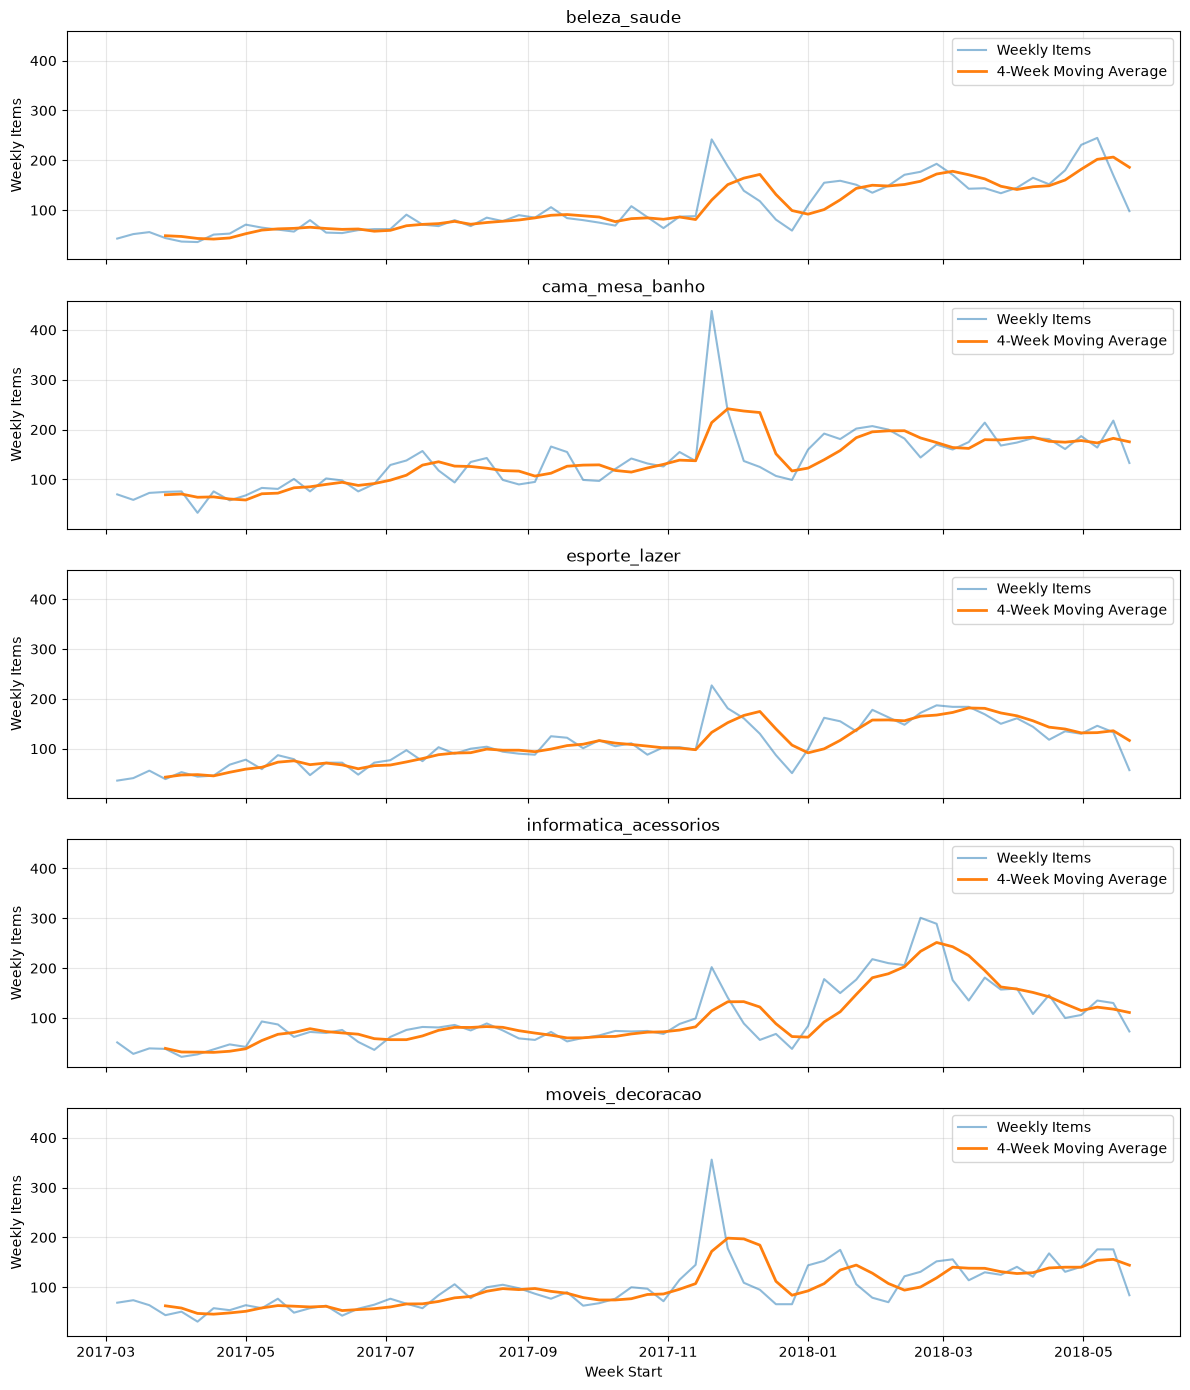

In [8]:
# TASK B-07-4. 상품군별 주간 수요 시각화 (+ 4주 이동평균)
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(12,14), sharex=True, sharey=True)

for ax, (category, group) in zip(axes, training_df.groupby('product_category_name')):
    group = group.sort_values('week_start').copy()
    group['ma_4'] = group['weekly_items'].rolling(window=4).mean()
    ax.plot(group['week_start'], group['weekly_items'], label='Weekly Items', alpha=0.5)
    ax.plot(group['week_start'], group['ma_4'], label='4-Week Moving Average', linewidth=2)
    ax.set_title(category)
    ax.set_ylabel('Weekly Items')
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel('Week Start')
plt.tight_layout()
plt.show()

## B-07-5. 주간 수요 급증·급감 구간 분석

**목적:** 학습 구간의 전주 대비 증감량과 증감률을 계산하고, 여러 상품군에서 동시에 발생한 급격한 변화가 있는지 확인한다.

$$ r_t = \frac{Y_t - Y_{t-1}}{Y_{t-1}} \times 100 $$

이벤트 원인은 현재 주문·상품군 데이터만으로 확정할 수 없다. 증감률과 절대 증감량을 함께 확인한다.

In [9]:
# TASK B-07-5. 주간 수요 급증·급감 분석
change_df = training_df.sort_values(['product_category_name','week_start']).copy()

# 1. 전주 대비 증감량
change_df['weekly_diff'] = (
    change_df.groupby('product_category_name')['weekly_items'].diff()
)
# 2. 전주 대비 증감률 (%)
change_df['wow_pct'] = (
    change_df.groupby('product_category_name')['weekly_items'].pct_change() * 100
)

print('증감량/증감률 확인')
display(change_df.head(10))
print('\n증가율 상위 5개 관측치')
display(change_df.nlargest(5,'wow_pct'))
print('\n감소율 상위 5개 관측치')
display(change_df.nsmallest(5,'wow_pct'))
print('\n2017-11-20 상품군별 증감')
display(change_df[change_df['week_start'] == '2017-11-20'])

증감량/증감률 확인


,week_start,product_category_name,weekly_items,weekly_diff,wow_pct
0,2017-03-06,beleza_saude,43,NaN,NaN
1,2017-03-13,beleza_saude,52,9.0,20.930233
2,2017-03-20,beleza_saude,56,4.0,7.692308
3,2017-03-27,beleza_saude,44,-12.0,-21.428571
4,2017-04-03,beleza_saude,37,-7.0,-15.909091
5,2017-04-10,beleza_saude,36,-1.0,-2.702703
6,2017-04-17,beleza_saude,51,15.0,41.666667
7,2017-04-24,beleza_saude,53,2.0,3.921569
8,2017-05-01,beleza_saude,71,18.0,33.962264
9,2017-05-08,beleza_saude,65,-6.0,-8.450704



증가율 상위 5개 관측치


,week_start,product_category_name,weekly_items,weekly_diff,wow_pct
113,2017-11-20,cama_mesa_banho,438,301.0,219.708029
37,2017-11-20,beleza_saude,242,154.0,175.000000
341,2017-11-20,moveis_decoracao,356,211.0,145.517241
189,2017-11-20,esporte_lazer,227,129.0,131.632653
82,2017-04-17,cama_mesa_banho,76,43.0,130.303030



감소율 상위 5개 관측치


,week_start,product_category_name,weekly_items,weekly_diff,wow_pct
215,2018-05-21,esporte_lazer,57,-76.0,-57.142857
81,2017-04-10,cama_mesa_banho,33,-43.0,-56.578947
367,2018-05-21,moveis_decoracao,84,-92.0,-52.272727
342,2017-11-27,moveis_decoracao,178,-178.0,-50.000000
114,2017-11-27,cama_mesa_banho,237,-201.0,-45.890411



2017-11-20 상품군별 증감


,week_start,product_category_name,weekly_items,weekly_diff,wow_pct
37,2017-11-20,beleza_saude,242,154.0,175.000000
113,2017-11-20,cama_mesa_banho,438,301.0,219.708029
189,2017-11-20,esporte_lazer,227,129.0,131.632653
265,2017-11-20,informatica_acessorios,202,103.0,104.040404
341,2017-11-20,moveis_decoracao,356,211.0,145.517241


## B-07-6. 자기상관 및 정상성 탐색

**목적:** 학습 64주의 ACF·PACF 패턴을 확인하고, ADF 검정으로 단위근 존재 귀무가설을 검토한다.

- ACF: 시차별 자기상관
- PACF: 중간 시차의 선형 영향을 제거한 편자기상관
- ADF 귀무가설: 단위근이 존재한다
- 검정 설정: `regression='c'`(상수), `regression='ct'`(상수와 선형 추세), 유의수준 0.05

ADF 기각 실패는 단위근이 존재함을 입증하는 것이 아니며, 차분 여부는 예측 검증과 잔차 진단을 함께 고려한다.

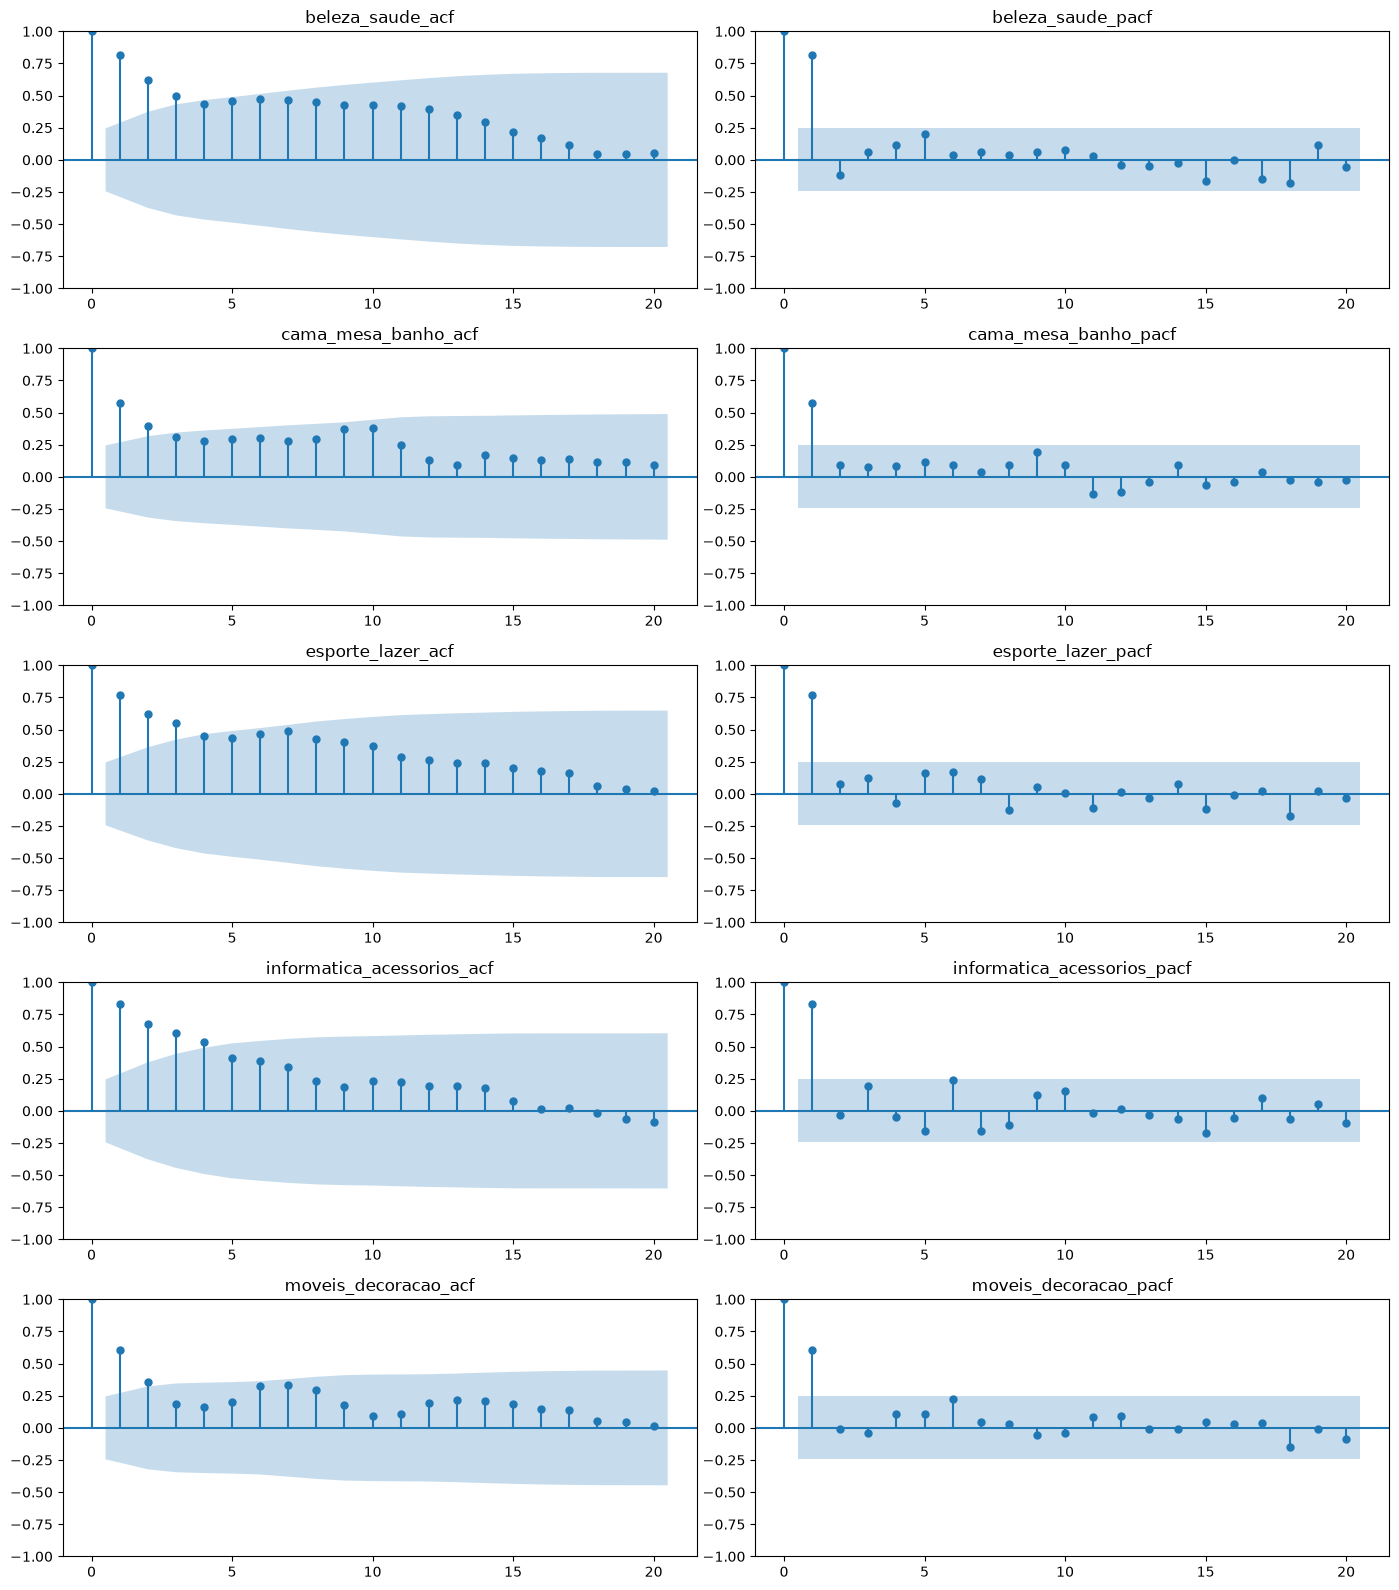

In [10]:
# TASK B-07-6. 상품군별 ACF/PACF (학습 64주)
fig, axes = plt.subplots(5, 2, figsize=(14,16))

for i, (category, group) in enumerate(training_df.groupby('product_category_name')):
    y = group.sort_values('week_start')['weekly_items']
    plot_acf(y, lags=20, ax=axes[i,0])
    plot_pacf(y, lags=20, ax=axes[i,1])
    axes[i,0].set_title(f'{category}_acf')
    axes[i,1].set_title(f'{category}_pacf')

plt.tight_layout()
plt.show()

In [11]:
# TASK B-07-6. 상품군별 ADF 단위근 검정 비교
adf_results = []

for category, group in training_df.groupby('product_category_name'):
    y = group.sort_values('week_start')['weekly_items']
    adf_stat_c, p_value_c, *_ = adfuller(y, result_object=False)
    adf_stat_ct, p_value_ct, *_ = adfuller(y, regression='ct', result_object=False)
    adf_results.append({
        'category': category,
        'adf_stat_c': adf_stat_c,
        'p_value_c': p_value_c,
        'adf_stat_ct': adf_stat_ct,
        'p_value_ct': p_value_ct,
    })

adf_results_df = pd.DataFrame(adf_results)
display(adf_results_df.round(6))

,category,adf_stat_c,p_value_c,adf_stat_ct,p_value_ct
0,beleza_saude,-2.587659,0.095575,-5.699990,0.000009
1,cama_mesa_banho,-4.111716,0.000926,-5.755456,0.000007
2,esporte_lazer,-2.784168,0.060571,-3.408428,0.050272
3,informatica_acessorios,-2.407285,0.139691,-2.902157,0.161519
4,moveis_decoracao,-3.889053,0.002117,-5.182677,0.000094


### ADF 결과 해석

**5% 유의수준에서 단위근 귀무가설 기각:**
- `c`, `ct` 모두 기각: `cama_mesa_banho`, `moveis_decoracao`
- `ct`만 기각: `beleza_saude`
- 둘 다 기각 실패: `esporte_lazer`, `informatica_acessorios`

`esporte_lazer`의 `ct` p-value는 **0.050272**로 0.05보다 크므로 기각 실패한다. ADF 결과 하나로 정상성 여부나 최종 ARIMA 차분 차수를 확정하지 않는다.

## B-07. 탐색적 시계열 분석 종합 결과

### 1. 상품군별 수요 추세 및 변동성

5개 상품군의 학습 시계열에서 2017년 초반 대비 후반의 주간 주문 수량이 대체로 높아지는 양상을 확인하였다. 4주 이동평균에서도 전반적인 수준 변화가 보였지만, 상품군별 추세의 형태는 같지 않았다. `beleza_saude`는 후반부까지 증가하는 양상을 보였고, `informatica_acessorios`는 2018년 2월경 급증한 뒤 감소하였다. 이동평균은 수요 충격에 후행하므로 이를 모두 지속적 추세로 해석할 수는 없다.

### 2. 주요 수요 급증·급감 구간

2017-11-20 주차에 5개 상품군 모두 전주 대비 100% 이상 증가했으며, 전체 증가율 상위 5개 관측치 가운데 4개가 해당 주차였다. 2017-11-27 주차에는 일부 상품군에서 큰 폭으로 감소했으며, 2018-05-21 주차에도 복수 상품군의 동반 감소가 관찰됐다. 해당 주차의 원인을 이벤트나 프로모션으로 확정할 자료는 없다.

### 3. 자기상관 및 정상성

ACF에서는 대부분 상품군의 Lag 1 자기상관이 뚜렷하며, PACF에서는 주로 Lag 1만 신뢰구간 밖으로 나타났다. AR(1)을 초기 후보로 고려할 수 있으나 최적 차수를 확정하는 근거는 아니다. ADF 검정에서는 상품군과 상수/추세항 설정에 따라 단위근 귀무가설 기각 여부가 달라졌다. 특히 `esporte_lazer`와 `informatica_acessorios`는 두 설정 모두에서 기각하지 못했다.

### 4. 예측 모델링에 대한 시사점

Naive 기준 모형을 먼저 구축해 최소 성능 기준을 확인하고, 수준·추세를 반영한 ETS와 자기상관을 고려한 ARIMA를 비교한다. 모델 후보 및 차분 차수는 학습 64주 내 Rolling-origin 검증과 잔차 진단을 함께 활용해 선택한다. 1~4주 예측 성능은 MAE·WAPE를 중심으로 평가하고, 마지막 12주는 최종 평가 전까지 사용하지 않는다.

**한계:** 상품군별 학습 관측치 64개로는 연간 계절성을 신뢰성 있게 추정하기 어렵다. 예측 대상은 구매 시점 기준 주문 상품 항목 수이며, 재고·프로모션 등 외생 요인을 관측하지 못한다.

In [12]:
# TASK B-07-7. 최종 데이터 검증
assert len(df) == 380, '전체 데이터는 380행이어야 합니다.'
assert len(training_df) == 320, '학습 데이터는 320행이어야 합니다.'
assert len(test_df) == 60, '평가 데이터는 60행이어야 합니다.'
assert training_df['week_start'].max() < test_df['week_start'].min(), '학습·평가 구간이 겹칩니다.'
assert df[['product_category_name','week_start']].duplicated().sum() == 0, '상품군 × 주차 중복이 존재합니다.'
assert df.isna().sum().sum() == 0, '결측값이 존재합니다.'
assert (week_diff == pd.Timedelta(days=7)).all(), '주차가 연속되지 않습니다.'
assert training_df.groupby('product_category_name')['week_start'].nunique().eq(64).all()
assert test_df.groupby('product_category_name')['week_start'].nunique().eq(12).all()
print('B-07 최종 데이터 검증: PASS')

B-07 최종 데이터 검증: PASS


## 결론 및 후속 작업

- 상품군별 76주 시계열 자료를 검증하고, 학습 64주·최종 평가 12주로 시간순 분리했다.
- 4주 이동평균으로 전반적인 수요 수준 변화를 확인했고, 2017-11-20의 5개 상품군 공통 급증을 정량적으로 검증했다.
- ACF·PACF에서는 최근 주차의 자기상관이 나타났으며, ADF 검정에서는 상품군별로 다른 결과가 확인됐다.
- **다음 단계(B-08):** Naive Forecast 구축 → 학습 구간 내부 Rolling-origin 평가 → ETS·Auto-ARIMA와 비교 → 마지막 12주 최종 평가.